# Проект: Влияние приложения для медитации на время засыпания

Тема «Постановка и проверка гипотез» \
уровень: начальный

---

## Сценарий

Компания разработала мобильное приложение с вечерними медитациями. Чтобы понять, помогает ли оно быстрее засыпать,
провели небольшое исследование. **Около 50 добровольцев** в течение одной недели фиксировали, сколько минут им требуется,
чтобы заснуть (среднее за неделю). Затем в течение 4 недель они пользовались приложением и ещё одну неделю
снова фиксировали время засыпания.

Данные получены **выгрузкой из системы сбора анкет**, поэтому, как и в реальной работе, они могут содержать ошибки.
Перед анализом их нужно проверить и очистить.

**Бизнес-вопрос:** *сокращает ли использование приложения время засыпания?*

Вы работаете аналитиком и должны ответить на него с помощью проверки статистических гипотез.

## Описание данных

| Столбец | Описание |
|---|---|
| `participant_id` | Идентификатор участника |
| `age` | Возраст участника (полных лет) |
| `before_min` | Среднее время засыпания (мин) за неделю **до** использования приложения |
| `after_min` | Среднее время засыпания (мин) за неделю **после** 4 недель использования |

Данные **парные**: каждая строка — один и тот же человек, измеренный дважды.
Возрастных групп в исходных данных **нет**: их нужно сформировать самостоятельно (задание 2).

## Допущения (упрощения для учебного проекта)

- Участники независимы друг от друга.
- Уровень значимости $\alpha = 0.05$ для всех проверок.
- Контрольной группы нет, поэтому причинно-следственные выводы ограничены (это нужно будет отметить в выводах).
- Допустимые значения (используются при очистке): время засыпания от **5 до 180 минут**, возраст от **18 до 80 лет**.

## Правила выполнения

1. Ячейку с генерацией данных **не изменяйте**. Также **нет необходимости изучать её код**: в реальной работе у вас нет кода, создавшего выгрузку, и проблемы в данных нужно находить анализом самой таблицы.
2. Каждый график должен иметь заголовок, подписи осей и (если нужно) легенду.
3. Решения о гипотезах, очистке данных и выбор тестов нужно **обосновывать словами**, а не только кодом.
4. Выводы формулируйте на языке бизнеса: без фраз вида «отвергаем H₀» в итоговом заключении.
5. Ноутбук должен выполняться целиком сверху вниз без ошибок (**Kernel → Restart & Run All**).

## Критерии оценки

| № | Задание | Баллы |
|---|---|:---:|
| 1 | Формулировка гипотез | 2 |
| 2 | Аудит и очистка данных, формирование возрастных групп | 4 |
| 3 | Разведочный анализ и графики | 2 |
| 4 | Проверка нормальности | 2 |
| 5 | Парный t-критерий и доверительный интервал | 2 |
| 6 | Критерий Уилкоксона | 1 |
| 7 | Сравнение с ошибочным непарным тестом | 2 |
| 8 | Размер эффекта | 1 |
| 9 | Гипотеза о доле улучшивших | 1 |
| 10 | Итоговые выводы | 1 |
| 11 | Оформление проекта (репозиторий, `requirements.txt`, воспроизводимость) | 2 |
| | **Итого** | **20** |
| ★ | Бонусное задание | +2 |

## Подготовка

Импортируйте нужные библиотеки в ячейке ниже (часть уже указана). При необходимости добавьте свои.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")

ALPHA = 0.05   # уровень значимости

### Данные

Выполните ячейку ниже. **Не изменяйте её и не изучайте её код** (см. правила выше): фиксированное зерно генератора (`seed`) гарантирует, что у всех получатся одинаковые данные.

In [2]:
rng = np.random.default_rng(150)
n = 50

age = rng.integers(18, 61, size=n).astype(float)
before = rng.normal(35, 10, n)
effect = np.where(age < 35, -4, -1)
after = before + rng.normal(effect, 4.5)

df = pd.DataFrame({
    "participant_id": range(1, n + 1),
    "age": age,
    "before_min": np.clip(before.round(), 5, None).astype(object),
    "after_min": np.clip(after.round(), 5, None).astype(object),
})

# --- Имитация реальной выгрузки: в ней бывают сбои и ошибки ввода ---
df.loc[[3, 17], "after_min"] = np.nan
df.loc[29, "before_min"] = np.nan
df.loc[8, "after_min"] = -20
df.loc[22, "before_min"] = 999
df.loc[41, "after_min"] = 400
df.loc[12, "before_min"] = f"{float(df.loc[12, 'before_min']):.1f}".replace(".", ",")
df.loc[36, "after_min"] = f"{float(df.loc[36, 'after_min']):.1f}".replace(".", ",")
df.loc[[5, 14], "age"] = np.nan
df.loc[19, "age"] = 0
df.loc[33, "age"] = 150
df = pd.concat([df, df.loc[[10, 25]]], ignore_index=True)
df = df.sample(frac=1, random_state=1).reset_index(drop=True)

df.head(10)

,participant_id,age,before_min,after_min
0,32,52.0,31.0,26.0
1,3,42.0,30.0,32.0
2,43,30.0,30.0,24.0
3,33,31.0,28.0,18.0
4,31,30.0,28.0,25.0
5,46,54.0,24.0,21.0
6,34,150.0,33.0,29.0
7,39,24.0,28.0,25.0
8,45,19.0,56.0,57.0
9,20,0.0,35.0,30.0


---
## Задание 1. Формулировка гипотез (2 балла)

**Что нужно сделать.** Запишите нулевую и альтернативную гипотезы для бизнес-вопроса
«сокращает ли приложение время засыпания?».

### Ваш ответ

**Определение разности:** $d_i = \text{after}_i - \text{before}_i$ — время засыпания участника $i$ после 4 недель использования приложения минус его время засыпания до. Если человек стал засыпать быстрее, разность **отрицательная**.

**Параметр:** $\mu_d$ — среднее изменение времени засыпания (в минутах) в генеральной совокупности пользователей, похожих на участников исследования.

**H₀:** $\mu_d = 0$ (в среднем время засыпания не меняется; формально $\mu_d \ge 0$ — не сокращается).

**H₁:** $\mu_d < 0$ (в среднем время засыпания сокращается).

**Обоснование типа альтернативы:** компания хочет доказать конкретное направление эффекта — что приложение *сокращает* время засыпания, поэтому выбираем **левостороннюю** альтернативу; направление определено логикой бизнес-вопроса до просмотра данных. Увеличение времени засыпания для бизнеса означало бы то же решение, что и отсутствие эффекта («приложение не помогает»).

**Правило принятия решения:** при уровне значимости $\alpha = 0.05$: если p-value $< 0.05$ — отвергаем $H_0$ в пользу $H_1$ (сокращение статистически значимо); если p-value $\ge 0.05$ — оснований отвергнуть $H_0$ нет.

---
## Задание 2. Аудит и очистка данных, формирование возрастных групп (4 балла)

**Что нужно сделать.** Исходная таблица `df` получена выгрузкой и **содержит проблемы с качеством данных**.
Вам нужно (1) найти их, (2) устранить по заданным правилам, (3) сформировать возрастные группы,
(4) зафиксировать, что и сколько было исправлено. Результат сохраните в новый датафрейм **`df_clean`**:
**все дальнейшие задания выполняются только на нём.** Исходный `df` не изменяйте (работайте с копией).

### 2.1. Аудит (поиск проблем)

Выведите и кратко прокомментируйте (по одному предложению на пункт):
- размер таблицы, типы столбцов, число непустых значений в каждом столбце;
- число пропусков по столбцам;
- число полных дубликатов строк и повторов `participant_id`;
- минимальные и максимальные значения числовых столбцов;
- столбцы, в которых тип данных **не соответствует ожидаемому** (какие значения этому мешают?).

Составьте **список обнаруженных проблем** (что именно не так и в каких столбцах).

### 2.2. Очистка по правилам

Применяйте правила **строго в указанном порядке**:

| № | Правило |
|---|---|
| 1 | **Типы.** Столбцы `before_min` и `after_min` привести к числовому типу. Значения, записанные текстом с десятичной запятой (например, `"31,0"`), преобразовать в числа. Значения, которые преобразовать невозможно, считать пропусками. |
| 2 | **Дубликаты.** Удалить полные дубликаты строк (оставить первое вхождение). |
| 3 | **Допустимые диапазоны.** Время засыпания допустимо в диапазоне **[5; 180]** минут, возраст допустим в диапазоне **[18; 80]** лет. Значения вне диапазона считать ошибками и заменить на пропуски. |
| 4 | **Неполные пары.** Удалить участников, у которых отсутствует **хотя бы одно** из двух значений времени (`before_min`, `after_min`). Участников с неизвестным возрастом **не удалять**: возраст нужен только для возрастных групп. |

### 2.3. Формирование возрастных групп

Создайте в `df_clean` столбец `age_group` по правилу:

| Условие | Значение `age_group` |
|---|---|
| `age` < 35 | `"до 35"` |
| `age` ≥ 35 | `"35 и старше"` |
| возраст неизвестен (пропуск) | пропуск (не заполнять средним и не относить ни к одной группе) |

### 2.4. Журнал очистки

Оформите **таблицей** (`pd.DataFrame`) журнал: для каждого шага — что сделано, сколько значений или строк затронуто, сколько строк осталось после шага.
Затем ответьте письменно (2–3 предложения): **почему** участников с пропусками во времени мы удаляем, а не заполняем средним значением?

**Контроль результата:** в `df_clean` должно остаться **44 строки**, а столбец `age_group` должен быть заполнен у **40** из них.
Если у вас получились другие числа, проверьте порядок применения правил.

### Подсказки

**Аудит.**
- `df.info()` показывает типы столбцов и число непустых значений: если столбец с числами имеет тип `object`, в нём есть текстовые значения.
- Пропуски: `df.isna().sum()`. Полные дубликаты: `df.duplicated().sum()`. Повторы только по идентификатору: `.duplicated()` у столбца `participant_id`.
- `df.describe()` по умолчанию описывает только числовые столбцы. Чтобы увидеть, какие именно значения в текстовом столбце «не числа», преобразуйте
  его функцией `pd.to_numeric(..., errors="coerce")`: всё, что не удалось преобразовать, станет `NaN`. Сравните с исходным столбцом и найдите значения,
  которые превратились в `NaN`, хотя раньше пропусками не были.
- Нереальные значения проще всего найти, отсортировав столбец (`sort_values`) и посмотрев на самые маленькие и самые большие значения,
  либо построив гистограмму или boxplot **после** преобразования типа.

**Очистка.**
- Работайте с копией: `df_clean = df.copy()`. Это защитит исходные данные и избавит от предупреждения `SettingWithCopyWarning`.
- Замена запятой на точку: у текстового столбца есть `.str.replace(",", ".")`. Но в столбце смешаны числа и строки, поэтому сначала приведите всё к строкам
  (`.astype(str)`), а затем преобразуйте в числа через `pd.to_numeric(..., errors="coerce")`. Пропуски при этом снова станут `NaN`.
- Дубликаты: `drop_duplicates()`.
- Замена значений вне диапазона на пропуски: можно через булеву маску и `.loc[маска, столбец] = np.nan`, либо через `Series.where(...)` / `Series.between(...)`.
  Не забудьте, что условие нужно составить для **обеих границ**.
- Удаление неполных пар: `dropna(subset=[...])`. Обратите внимание на параметр `subset`: без него будут удалены и строки с неизвестным возрастом.
- После очистки типы столбцов `before_min` и `after_min` должны быть числовыми (`float`). Проверьте через `df_clean.dtypes`.

**Возрастные группы.**
- Вариант 1: `pd.cut(df_clean["age"], bins=[...], labels=[...], right=False)`. Подумайте, как параметр `right` влияет на то, куда попадает возраст ровно 35.
- Вариант 2: `np.where(условие, значение_если_верно, значение_если_неверно)`. **Ловушка:** сравнение с `NaN` всегда ложно (`NaN < 35` это `False`),
  поэтому при простом `np.where(age < 35, "до 35", "35 и старше")` неизвестный возраст молча попадёт в группу «35 и старше». Предусмотрите отдельную обработку пропусков.
- Проверьте результат: `df_clean["age_group"].value_counts(dropna=False)` покажет и число пропусков.

**Журнал и обоснование.**
- Журнал удобно вести, запоминая `len(df_clean)` до и после каждого шага и добавляя строки в список словарей, из которого потом строится `pd.DataFrame`.
- Для обоснования подумайте: что произойдёт с парной разностью $d_i = \text{after}_i - \text{before}_i$, если подставить вместо пропущенного значения среднее по столбцу?
  Будет ли такая «разность» отражать реальное изменение у конкретного человека?

### Ваше решение

### 2.1. Аудит данных

In [3]:
# Размер, типы столбцов и число непустых значений
print("Размер таблицы:", df.shape)
df.info()

Размер таблицы: (52, 4)
<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   participant_id  52 non-null     int64  
 1   age             50 non-null     float64
 2   before_min      51 non-null     object 
 3   after_min       50 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 1.8+ KB


**Список обнаруженных проблем:**

1. **Неверный тип данных:** столбцы `before_min` и `after_min` имеют тип `object` вместо числового — в них есть значения, записанные текстом с десятичной запятой (`"37,0"` в `before_min`, `"18,0"` в `after_min`).
2. **Пропуски:** `before_min` — 1, `after_min` — 2, `age` — 2.
3. **Полные дубликаты строк:** 2 строки (участники выгружены дважды; повторы `participant_id` — те же 2 строки).
4. **Значения вне допустимого диапазона времени [5; 180]:** `before_min = 999`, `after_min = 400`, `after_min = -20` (отрицательное время невозможно).
5. **Значения вне допустимого диапазона возраста [18; 80]:** `age = 0` и `age = 150`.

### 2.2–2.3. Очистка и возрастные группы

In [4]:
df_clean = df.copy()
log = []  # журнал очистки


def add_log(step, action, affected):
    log.append({"шаг": step, "что сделано": action, "затронуто": affected, "строк осталось": len(df_clean)})


# Правило 1. Типы: текст с запятой -> число, непреобразуемое -> NaN
affected = 0
for col in ["before_min", "after_min"]:
    was_na = df_clean[col].isna()
    is_text = df_clean[col].apply(lambda v: isinstance(v, str))
    df_clean[col] = pd.to_numeric(df_clean[col].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    affected += int(is_text.sum())
    new_na = int((df_clean[col].isna() & ~was_na).sum())
    print(f"{col}: текстовых значений исправлено {is_text.sum()}, новых пропусков после преобразования {new_na}")
add_log(1, "before_min/after_min приведены к числу (запятая -> точка)", affected)

# Правило 2. Полные дубликаты строк
n_dup = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates(keep="first")
add_log(2, "удалены полные дубликаты строк", n_dup)

# Правило 3. Значения вне допустимых диапазонов -> NaN
affected = 0
for col, low, high in [("before_min", 5, 180), ("after_min", 5, 180), ("age", 18, 80)]:
    bad = df_clean[col].notna() & ~df_clean[col].between(low, high)
    print(f"{col}: вне [{low}; {high}] -> {df_clean.loc[bad, col].tolist()}")
    df_clean.loc[bad, col] = np.nan
    affected += int(bad.sum())
add_log(3, "значения вне диапазонов заменены на пропуски", affected)

# Правило 4. Неполные пары (возраст не учитываем)
before_len = len(df_clean)
df_clean = df_clean.dropna(subset=["before_min", "after_min"]).reset_index(drop=True)
add_log(4, "удалены участники без before_min или after_min", before_len - len(df_clean))

df_clean.dtypes

before_min: текстовых значений исправлено 1, новых пропусков после преобразования 0
after_min: текстовых значений исправлено 1, новых пропусков после преобразования 0
before_min: вне [5; 180] -> [999.0]
after_min: вне [5; 180] -> [400.0, -20.0]
age: вне [18; 80] -> [150.0, 0.0]


participant_id      int64
age               float64
before_min        float64
after_min         float64
dtype: object

In [5]:
# right=False: возраст ровно 35 попадает в «35 и старше»; NaN в age остаётся NaN в age_group
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[-np.inf, 35, np.inf],
    labels=["до 35", "35 и старше"],
    right=False,
)
add_log("2.3", "создан столбец age_group", int(df_clean["age_group"].notna().sum()))
df_clean["age_group"].value_counts(dropna=False)

age_group
35 и старше    21
до 35          19
NaN             4
Name: count, dtype: int64

### 2.4. Журнал очистки

In [6]:
log_df = pd.DataFrame(log)
display(log_df)

print("Строк в df_clean:", len(df_clean))
print("Заполнено age_group:", df_clean["age_group"].notna().sum())
assert len(df_clean) == 44 and df_clean["age_group"].notna().sum() == 40

,шаг,что сделано,затронуто,строк осталось
0,1,before_min/after_min приведены к числу (запята...,2,52
1,2,удалены полные дубликаты строк,2,50
2,3,значения вне диапазонов заменены на пропуски,5,50
3,4,удалены участники без before_min или after_min,6,44
4,2.3,создан столбец age_group,40,44


Строк в df_clean: 44
Заполнено age_group: 40


**Почему удаляем, а не заполняем средним (2–3 предложения):** анализ строится на парной разности $d_i = \text{after}_i - \text{before}_i$ конкретного человека, а если подставить вместо пропуска среднее по столбцу, «разность» будет сравнивать человека со средним по выборке, а не с самим собой, — это выдуманное изменение. Такая подстановка искусственно занижает разброс и может как создать, так и скрыть эффект. Участников с неизвестным возрастом мы оставляем, потому что возраст не участвует в основной проверке и нужен только для деления на группы.

---
## Задание 3. Разведочный анализ разностей (2 балла)

**Что нужно сделать.** Работая с **очищенными данными `df_clean`**, создайте столбец разностей и изучите его визуально.

**Требования:**
1. Добавьте в `df_clean` столбец `diff = after_min − before_min`.
2. Выведите описательную статистику `diff` (среднее, std, медиана, мин, макс).
3. Подсчитайте, у скольких участников время засыпания **сократилось**, **не изменилось**, **выросло**.
4. Постройте (seaborn) **гистограмму с KDE** и **boxplot** для `diff`. На гистограмме отметьте вертикальными линиями значение 0 и среднее.
5. Кратко опишите (2–3 предложения): куда смещено распределение относительно нуля, есть ли выбросы.

### Подсказки

- Обратите внимание на знак: при таком определении разности **улучшение — это отрицательное значение**. Не перепутайте при подсчёте.
- Для подсчёта удобно использовать булевы условия: `(df["diff"] < 0).sum()`.
- Гистограмма: `sns.histplot(..., kde=True)`. Вертикальная линия: `plt.axvline(x, linestyle="--")` или `ax.axvline(...)`.
- Два графика рядом: `fig, axes = plt.subplots(1, 2, figsize=(12, 4))`, затем параметр `ax=axes[0]`, `ax=axes[1]`.
- Не забудьте заголовки и подписи осей: `ax.set_title(...)`, `ax.set_xlabel(...)`.

### Ваше решение

In [7]:
df_clean["diff"] = df_clean["after_min"] - df_clean["before_min"]

display(df_clean["diff"].agg(["mean", "std", "median", "min", "max"]).to_frame("diff"))

decreased = int((df_clean["diff"] < 0).sum())
unchanged = int((df_clean["diff"] == 0).sum())
increased = int((df_clean["diff"] > 0).sum())
print(f"Время засыпания сократилось: {decreased}, не изменилось: {unchanged}, выросло: {increased}")

,diff
mean,-3.113636
std,4.183111
median,-3.000000
min,-11.000000
max,8.000000


Время засыпания сократилось: 33, не изменилось: 2, выросло: 9


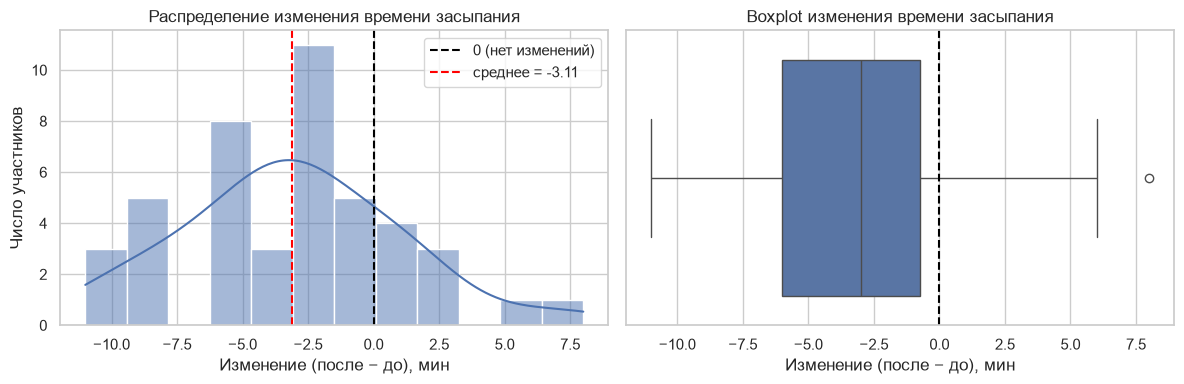

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_clean["diff"], kde=True, bins=12, ax=axes[0])
axes[0].axvline(0, color="black", linestyle="--", label="0 (нет изменений)")
axes[0].axvline(df_clean["diff"].mean(), color="red", linestyle="--",
                label=f"среднее = {df_clean['diff'].mean():.2f}")
axes[0].set_title("Распределение изменения времени засыпания")
axes[0].set_xlabel("Изменение (после − до), мин")
axes[0].set_ylabel("Число участников")
axes[0].legend()

sns.boxplot(x=df_clean["diff"], ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Boxplot изменения времени засыпания")
axes[1].set_xlabel("Изменение (после − до), мин")

plt.tight_layout()
plt.show()

**Описание графиков (2–3 предложения):** распределение разностей заметно смещено влево от нуля: среднее ≈ −3.1 мин, медиана −3 мин, у 33 из 44 участников время засыпания сократилось. Форма распределения близка к колоколообразной, без тяжёлых хвостов; на boxplot отдельные точки за «усами» не выделяются, явных выбросов после очистки нет. Небольшая часть участников (9 человек) стала засыпать дольше — максимум +8 мин.

---
## Задание 4. Проверка нормальности разностей (2 балла)

**Что нужно сделать.** Выясните, можно ли считать разности `diff` приблизительно нормальными.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ для теста Шапиро-Уилка.
2. Проведите тест, выведите статистику $W$ и p-value.
3. Постройте Q-Q график (любой библиотекой).
4. Сформулируйте вывод (2–3 предложения): применим ли парный t-критерий? Что вы будете считать основным тестом, а что — проверочным?

### Подсказки

- Нормальность проверяется для **разностей**, а не для `before_min` и `after_min` по отдельности: парный t-тест — это тест для одной выборки `diff`.
- Тест: `stats.shapiro(...)`. Он возвращает статистику и p-value.
- Q-Q график: `stats.probplot(данные, dist="norm")` возвращает пару: теоретические и выборочные квантили, а также параметры прямой.
  Их можно нарисовать точками (`plotly` или `matplotlib`) и добавить линию.
- Помните: $p > 0.05$ означает «нет оснований отвергать нормальность», а не «нормальность доказана».
- Объём выборки (50) позволяет по центральной предельной теореме рассчитывать на приближённую нормальность среднего,
  даже если нормальность разностей не идеальна. Но график всё равно стоит посмотреть: нет ли сильных выбросов?

### Ваше решение

In [9]:
w_stat, p_shapiro = stats.shapiro(df_clean["diff"])
print(f"Шапиро-Уилк: W = {w_stat:.4f}, p-value = {p_shapiro:.4f}")

Шапиро-Уилк: W = 0.9786, p-value = 0.5786


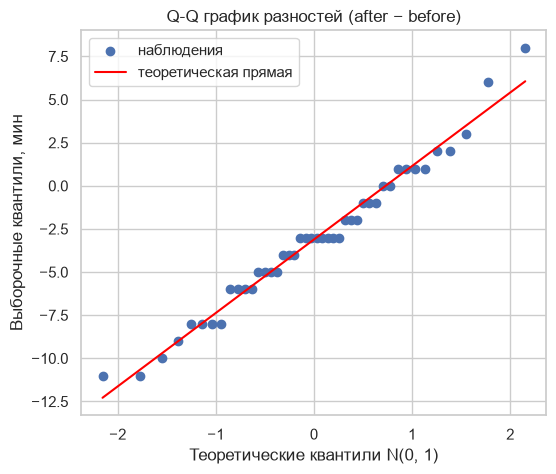

In [10]:
(osm, osr), (slope, intercept, r) = stats.probplot(df_clean["diff"], dist="norm")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(osm, osr, label="наблюдения")
ax.plot(osm, slope * osm + intercept, color="red", label="теоретическая прямая")
ax.set_title("Q-Q график разностей (after − before)")
ax.set_xlabel("Теоретические квантили N(0, 1)")
ax.set_ylabel("Выборочные квантили, мин")
ax.legend()
plt.show()

**Гипотезы Шапиро-Уилка:** $H_0$: разности `diff` распределены нормально; $H_1$: распределение разностей отличается от нормального.

**Вывод о нормальности и выборе тестов:** p-value ≈ 0.58 > 0.05, поэтому оснований отвергать нормальность нет (это не доказательство нормальности, но серьёзных отклонений не видно); точки на Q-Q графике лежат близко к прямой, сильных выбросов нет. При n = 44 к тому же работает ЦПТ для среднего, поэтому парный t-критерий применим — он будет **основным** тестом. Критерий Уилкоксона (не требует нормальности) и биномиальный тест знаков используем как **проверочные**.

---
## Задание 5. Парный t-критерий и доверительный интервал (2 балла)

**Что нужно сделать.** Проверьте гипотезу из задания 1 парным t-критерием.

**Требования:**
1. Посчитайте **вручную** (через `numpy`/`pandas`): среднее разностей $\bar d$, стандартное отклонение $s_d$,
   стандартную ошибку, статистику $t$ и число степеней свободы.
2. Получите p-value по распределению Стьюдента вручную (`scipy.stats.t`).
3. Проведите тест готовой функцией и убедитесь, что результаты совпадают.
4. Постройте двусторонний 95% доверительный интервал для $\mu_d$.
5. Запишите решение по правилу из задания 1 и интерпретацию в одном предложении.

### Подсказки

- Формула статистики: $t = \dfrac{\bar d}{s_d / \sqrt{n}}$, число степеней свободы $\text{df} = n - 1$.
- Стандартное отклонение выборки: `.std(ddof=1)` (в pandas `ddof=1` по умолчанию, в numpy — нет!).
- p-value вручную: используйте функцию выживания `stats.t.sf(...)` или функцию распределения `stats.t.cdf(...)`.
  Подумайте, какой «хвост» нужен для вашей $H_1$: левый или правый. Для левостороннего теста p-value равно $P(T \le t_{\text{набл}})$.
- Готовая функция: `stats.ttest_rel(a, b, alternative=...)`. Порядок аргументов важен: тест сравнивает `a` с `b`,
  а параметр `alternative` принимает `"two-sided"`, `"less"`, `"greater"`. Выберите значения так, чтобы они соответствовали вашей $H_1$.
- Доверительный интервал: `stats.t.interval(0.95, df=..., loc=среднее, scale=стандартная_ошибка)`.
- Если ваш ручной и готовый p-value не совпадают, проверьте знак $t$ и выбранный «хвост».

### Ваше решение

In [11]:
d = df_clean["diff"]
n_obs = len(d)
d_mean = d.mean()
s_d = d.std(ddof=1)
se_paired = s_d / np.sqrt(n_obs)
t_manual = d_mean / se_paired
dof = n_obs - 1
p_manual = stats.t.cdf(t_manual, dof)   # левосторонняя H1: P(T <= t_набл)

print(f"n = {n_obs}, среднее d = {d_mean:.4f}, s_d = {s_d:.4f}")
print(f"SE = {se_paired:.4f}, t = {t_manual:.4f}, df = {dof}")
print(f"p-value (вручную, левосторонний) = {p_manual:.3e}")

n = 44, среднее d = -3.1136, s_d = 4.1831
SE = 0.6306, t = -4.9374, df = 43
p-value (вручную, левосторонний) = 6.212e-06


In [12]:
t_res = stats.ttest_rel(df_clean["after_min"], df_clean["before_min"], alternative="less")
print(f"ttest_rel: t = {t_res.statistic:.4f}, p-value = {t_res.pvalue:.3e}, df = {t_res.df}")
print("t совпадает:", np.isclose(t_res.statistic, t_manual), "| p-value совпадает:", np.isclose(t_res.pvalue, p_manual))

ttest_rel: t = -4.9374, p-value = 6.212e-06, df = 43
t совпадает: True | p-value совпадает: True


In [13]:
ci_low, ci_high = stats.t.interval(0.95, df=dof, loc=d_mean, scale=se_paired)
print(f"95% ДИ для среднего изменения: [{ci_low:.2f}; {ci_high:.2f}] мин")

95% ДИ для среднего изменения: [-4.39; -1.84] мин


**Решение по правилу и интерпретация:** p-value ≈ 6.2·10⁻⁶ < 0.05, поэтому отвергаем $H_0$ в пользу $H_1$: $\mu_d < 0$. После использования приложения участники в среднем засыпают на ≈ 3.1 мин быстрее (95% ДИ: от 1.8 до 4.4 мин сокращения), и такое снижение вряд ли объясняется случайностью.

---
## Задание 6. Критерий Уилкоксона (1 балл)

**Что нужно сделать.** Повторите проверку непараметрическим критерием знаковых рангов и сравните с t-тестом.

**Требования:**
1. Запишите в одном предложении, что проверяет критерий Уилкоксона в этой задаче.
2. Проведите тест с той же альтернативой, что и в задании 5.
3. Сравните p-value двух тестов и напишите, согласуются ли выводы.

### Подсказки

- Функция: `stats.wilcoxon(...)`. Ей можно передать сразу столбец разностей.
- Параметр `alternative` работает так же, как у t-теста.
- Нулевые разности (участники без изменений) по умолчанию исключаются из расчёта. Это нормально; можно упомянуть в комментарии, сколько их было.
- Если p-value двух тестов отличаются в 1.5–3 раза, но решение одинаково, это не противоречие: тесты используют разную информацию.

### Ваше решение

In [14]:
w_res = stats.wilcoxon(df_clean["diff"], alternative="less")
print(f"Уилкоксон: статистика = {w_res.statistic}, p-value = {w_res.pvalue:.3e}")
print("Нулевых разностей (исключены из расчёта):", int((df_clean["diff"] == 0).sum()))
print(f"Парный t-тест: p-value = {t_res.pvalue:.3e}")

Уилкоксон: статистика = 120.0, p-value = 1.625e-05
Нулевых разностей (исключены из расчёта): 2
Парный t-тест: p-value = 6.212e-06


**Что проверяет критерий:** критерий знаковых рангов Уилкоксона проверяет, смещено ли распределение разностей `after − before` относительно нуля (здесь — в сторону сокращения времени засыпания), используя ранги модулей разностей вместо самих значений.

**Сравнение с t-тестом:** p-value Уилкоксона ≈ 1.6·10⁻⁵, у t-теста ≈ 6.2·10⁻⁶ — оба намного меньше 0.05, выводы согласуются. Разница в p-value ожидаема: тесты используют разную информацию (ранги против самих значений), а 2 нулевые разности Уилкоксон исключил.

---
## Задание 7. Типичная ошибка: непарный тест (2 балла)

**Что нужно сделать.** Намеренно примените **неверный** тест для независимых выборок и объясните разницу с результатом задания 5.

**Требования:**
1. Проведите тест Уэлча для двух независимых выборок (`before_min` и `after_min`) с той же альтернативой.
2. Выведите в таблице: $t$, p-value и стандартную ошибку для **парного** и **непарного** тестов, а также корреляцию Пирсона между `before_min` и `after_min`.
3. Изменилось ли решение по $H_0$ при $\alpha = 0.05$?
4. Объясните разницу в 3–4 предложениях: почему результаты различаются и какой тест надёжнее.
5. Постройте диаграмму рассеяния `before_min` vs `after_min` с диагональю $y = x$ и прокомментируйте её (1–2 предложения).

### Подсказки

- Функция: `stats.ttest_ind(a, b, equal_var=False, alternative=...)`. Порядок `a` и `b` должен быть таким же, как в задании 5.
- Стандартная ошибка непарного теста: $\sqrt{\dfrac{s_a^2}{n} + \dfrac{s_b^2}{n}}$. Стандартная ошибка парного теста: $s_d / \sqrt{n}$ (вы её уже считали).
- Корреляция: `df["before_min"].corr(df["after_min"])`.
- Для объяснения ответьте на вопросы: чем различаются люди между собой (сильно или слабо)? Сколько из этой вариации «вычитается» при переходе
  к разностям? Что происходит со знаменателем статистики $t$?
- Диаграмма рассеяния: `px.scatter` или `sns.scatterplot`. Диагональ: линия между точками `(min, min)` и `(max, max)`.
  Точки ниже диагонали — участники, у которых время засыпания уменьшилось.

### Ваше решение

In [15]:
welch = stats.ttest_ind(df_clean["after_min"], df_clean["before_min"], equal_var=False, alternative="less")
print(f"Уэлч (непарный, ОШИБОЧНЫЙ для этих данных): t = {welch.statistic:.4f}, p-value = {welch.pvalue:.4f}")

Уэлч (непарный, ОШИБОЧНЫЙ для этих данных): t = -1.2717, p-value = 0.1035


In [16]:
se_unpaired = np.sqrt(df_clean["after_min"].var() / n_obs + df_clean["before_min"].var() / n_obs)
r_pearson = df_clean["before_min"].corr(df_clean["after_min"])

compare = pd.DataFrame({
    "тест": ["парный t-тест (верный)", "Уэлч, непарный (ошибочный)"],
    "t": [t_res.statistic, welch.statistic],
    "p-value": [t_res.pvalue, welch.pvalue],
    "SE": [se_paired, se_unpaired],
    "решение при α=0.05": [
        "отвергаем H0" if t_res.pvalue < ALPHA else "нет оснований отвергнуть H0",
        "отвергаем H0" if welch.pvalue < ALPHA else "нет оснований отвергнуть H0",
    ],
})
display(compare)
print(f"Корреляция Пирсона before_min vs after_min: r = {r_pearson:.3f}")

,тест,t,p-value,SE,решение при α=0.05
0,парный t-тест (верный),-4.937361,0.000006,0.630628,отвергаем H0
1,"Уэлч, непарный (ошибочный)",-1.271673,0.103472,2.448457,нет оснований отвергнуть H0


Корреляция Пирсона before_min vs after_min: r = 0.937


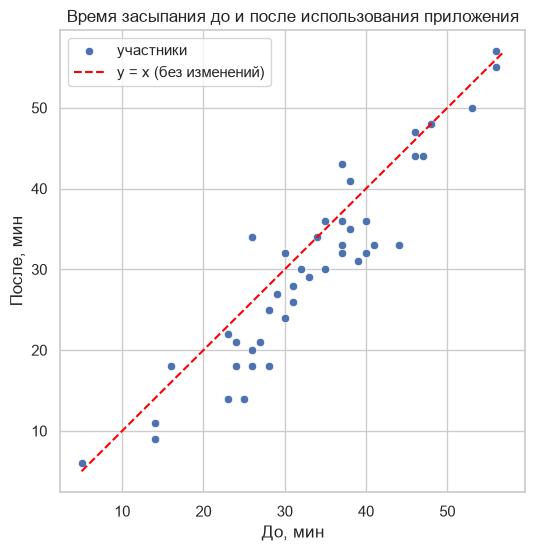

In [17]:
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(data=df_clean, x="before_min", y="after_min", ax=ax, label="участники")
lims = [min(df_clean["before_min"].min(), df_clean["after_min"].min()),
        max(df_clean["before_min"].max(), df_clean["after_min"].max())]
ax.plot(lims, lims, color="red", linestyle="--", label="y = x (без изменений)")
ax.set_title("Время засыпания до и после использования приложения")
ax.set_xlabel("До, мин")
ax.set_ylabel("После, мин")
ax.legend()
plt.show()

**Решение изменилось?** Да: непарный тест Уэлча даёт p-value ≈ 0.10 > 0.05 — «оснований отвергнуть $H_0$ нет», тогда как парный тест уверенно отвергает $H_0$.

**Объяснение разницы (3–4 предложения):** люди сильно различаются между собой по времени засыпания (стандартное отклонение ≈ 11–12 мин), и непарный тест включает весь этот межличностный разброс в стандартную ошибку (SE ≈ 2.4 мин). Измерения «до» и «после» у одного человека сильно связаны (r ≈ 0.94), и при переходе к разностям индивидуальные особенности вычитаются, остаётся только изменение (SE ≈ 0.63 мин). Знаменатель статистики $t$ в парном тесте почти в 4 раза меньше, поэтому тот же сдвиг среднего в ~3 мин становится хорошо заметен. Для парных данных надёжен парный тест: непарный нарушает своё же допущение о независимости выборок и теряет мощность.

**Комментарий к диаграмме:** точки вытянуты вдоль диагонали — тот, кто засыпал долго до, засыпает долго и после (высокая корреляция). Большинство точек лежит **ниже** линии $y = x$, то есть у большинства участников время засыпания уменьшилось.

---
## Задание 8. Размер эффекта (1 балл)

**Что нужно сделать.** Оцените практическую значимость эффекта.

**Требования:**
1. Рассчитайте Cohen's $d$ для парных данных.
2. Интерпретируйте по шкале Коэна (≈0.2 — малый, ≈0.5 — средний, ≈0.8 — большой).
3. Выразите средний эффект в минутах и в процентах от среднего исходного времени засыпания.
4. Напишите 1–2 предложения: почему p-value недостаточно для ответа на вопрос «насколько это существенно?».

### Подсказки

- Формула: $d_z = \dfrac{\bar d}{s_d}$, где $\bar d$ и $s_d$ — среднее и стандартное отклонение разностей.
- У вас эффект отрицательный (время уменьшилось). Для интерпретации по шкале используйте **модуль** значения.
- Процент от исходного уровня: среднее изменение, делённое на `df["before_min"].mean()`, умноженное на 100.

### Ваше решение

In [18]:
cohen_dz = d_mean / s_d
effect_pct = d_mean / df_clean["before_min"].mean() * 100


def cohen_label(value):
    v = abs(value)
    if v < 0.2:
        return "пренебрежимо малый"
    if v < 0.5:
        return "малый"
    if v < 0.8:
        return "средний"
    return "большой"


print(f"Cohen's d_z = {cohen_dz:.3f} -> {cohen_label(cohen_dz)} эффект (|d| ≈ 0.74, ближе к большому)")
print(f"Средний эффект: {d_mean:.2f} мин = {effect_pct:.1f}% от среднего исходного времени "
      f"({df_clean['before_min'].mean():.1f} мин)")

Cohen's d_z = -0.744 -> средний эффект (|d| ≈ 0.74, ближе к большому)


Средний эффект: -3.11 мин = -9.4% от среднего исходного времени (33.1 мин)


**Интерпретация:** $d_z \approx -0.74$ — эффект **средний, близкий к большому** по шкале Коэна: сокращение на ≈ 3.1 мин, это ≈ 9.4% от среднего исходного времени засыпания (≈ 33 мин). p-value показывает лишь то, насколько результат маловероятен при отсутствии эффекта, и зависит от размера выборки: при большом n даже крошечный эффект даст малое p-value. Поэтому для ответа «насколько это существенно» нужны размер эффекта и доверительный интервал в понятных единицах (минутах).

---
## Задание 9. Гипотеза о доле улучшивших (1 балл)

**Что нужно сделать.** Проверьте ещё одну гипотезу, не использующую величину изменения, а только его **направление**:
*«более чем у половины участников время засыпания сократилось»*.

**Требования:**
1. Определите параметр $p$ и запишите $H_0$ и $H_1$.
2. Определите, кого учитывать в расчёте (что делать с участниками, у которых разность равна 0).
3. Проведите **биномиальный тест** и выведите p-value.
4. Сформулируйте вывод в одном предложении.
5. Рассчитайте долю улучшивших и её 95% доверительный интервал.

### Подсказки

- Параметр: $p$ — доля участников (среди тех, у кого время изменилось), у которых оно **сократилось**.
  Если приложение не работает, сокращение и увеличение равновероятны, то есть $p = 0.5$.
- Участников с `diff == 0` исключите из расчёта: они не дают информации о направлении. Укажите, сколько их было.
- Функция: `stats.binomtest(k, n, p=0.5, alternative=...)`, где `k` — число «успехов» (улучшившихся), `n` — число участников с ненулевой разностью.
- У результата теста есть метод `.proportion_ci(confidence_level=0.95)` для доверительного интервала доли. Внимание: интервал строится
  в соответствии с `alternative` теста (при односторонней альтернативе он тоже односторонний, одна из границ будет 0 или 1).
  Для обычного двустороннего интервала вызовите `binomtest` с `alternative="two-sided"`.
- Сравните этот тест с t-тестом: что он «теряет» по сравнению с ним (подсказка: он не учитывает величину изменений) и почему всё равно полезен
  (подсказка: не требует нормальности и устойчив к выбросам).

### Ваше решение

**Параметр, H₀ и H₁:** $p$ — доля участников (среди тех, у кого время засыпания изменилось), у которых оно **сократилось**.

$H_0$: $p = 0.5$ (сокращение и увеличение равновероятны — приложение не влияет);
$H_1$: $p > 0.5$ (более чем у половины участников время засыпания сократилось) — односторонняя альтернатива, т.к. проверяем именно утверждение «более чем у половины».

Участников с `diff == 0` исключаем: они не дают информации о направлении изменения.

In [19]:
n_improved = int((df_clean["diff"] < 0).sum())
n_nonzero = int((df_clean["diff"] != 0).sum())
print(f"Исключено с нулевой разностью: {len(df_clean) - n_nonzero}")
print(f"Улучшили: {n_improved} из {n_nonzero}")

binom_res = stats.binomtest(n_improved, n_nonzero, p=0.5, alternative="greater")
print(f"Биномиальный тест (H1: p > 0.5): p-value = {binom_res.pvalue:.3e}")

share = n_improved / n_nonzero
ci = stats.binomtest(n_improved, n_nonzero, p=0.5, alternative="two-sided").proportion_ci(confidence_level=0.95)
print(f"Доля улучшивших: {share:.1%}, 95% ДИ (Клоппер-Пирсон): [{ci.low:.1%}; {ci.high:.1%}]")

Исключено с нулевой разностью: 2
Улучшили: 33 из 42
Биномиальный тест (H1: p > 0.5): p-value = 1.358e-04
Доля улучшивших: 78.6%, 95% ДИ (Клоппер-Пирсон): [63.2%; 89.7%]


**Вывод:** время засыпания сократилось у 33 из 42 участников с изменившимся результатом (≈ 79%, 95% ДИ ≈ 63–90%), p-value ≈ 0.00014 < 0.05 — доля улучшивших достоверно больше половины. Этот тест не учитывает, *насколько* изменилось время, поэтому менее чувствителен, чем t-тест, зато не требует нормальности и устойчив к выбросам — и его вывод совпадает с остальными.

---
## Задание 10. Итоговые выводы (1 балл)

**Что нужно сделать.** Подготовьте заключение для руководителя продукта (не статистика!).

**Требования.** Сводная таблица результатов и текст из 5–7 предложений, содержащий:
1. ответ на бизнес-вопрос и размер выборки после очистки (сколько участников вошло в анализ и сколько исключено);
2. величину эффекта с доверительным интервалом (в минутах);
3. долю участников, которым приложение помогло;
4. упоминание, что вывод устойчив (согласие нескольких тестов) или, наоборот, что есть расхождения;
5. **минимум два ограничения** исследования (подумайте про контрольную группу, длительность, самоотчёты участников, добровольность);
6. рекомендацию: что делать дальше.

### Подсказки

- Таблицу соберите через `pd.DataFrame` со столбцами: метод, статистика, p-value, решение при $\alpha$.
  Включите в неё и ошибочный непарный тест, пометив его.
- Пишите без жаргона: вместо «p < 0.05» — «различие вряд ли случайно».
- Помните, что **без контрольной группы** нельзя утверждать, что именно приложение привело к улучшению: на время засыпания могли повлиять
  другие факторы (сезон, привычки, ожидания участников).
- Хорошая рекомендация конкретна: например, «провести контролируемое исследование с группой сравнения», а не «нужно больше данных».

### Ваше решение

In [20]:
summary = pd.DataFrame([
    {"метод": "Парный t-тест (основной)", "статистика": f"t = {t_res.statistic:.2f}", "p-value": t_res.pvalue},
    {"метод": "Критерий Уилкоксона", "статистика": f"W = {w_res.statistic:.0f}", "p-value": w_res.pvalue},
    {"метод": "Биномиальный тест (доля улучшивших)", "статистика": f"{n_improved}/{n_nonzero}", "p-value": binom_res.pvalue},
    {"метод": "Уэлч, непарный (ОШИБОЧНЫЙ, для сравнения)", "статистика": f"t = {welch.statistic:.2f}", "p-value": welch.pvalue},
])
summary["решение при α = 0.05"] = np.where(summary["p-value"] < ALPHA, "эффект значим", "эффект не подтверждён")
display(summary)

print(f"Участников в анализе: {len(df_clean)} (исключено из {df['participant_id'].nunique()} уникальных: "
      f"{df['participant_id'].nunique() - len(df_clean)})")
print(f"Среднее изменение: {d_mean:.1f} мин, 95% ДИ [{ci_low:.1f}; {ci_high:.1f}] мин; Cohen's d = {cohen_dz:.2f}")
print(f"Доля улучшивших: {share:.0%}")

,метод,статистика,p-value,решение при α = 0.05
0,Парный t-тест (основной),t = -4.94,0.000006,эффект значим
1,Критерий Уилкоксона,W = 120,0.000016,эффект значим
2,Биномиальный тест (доля улучшивших),33/42,0.000136,эффект значим
3,"Уэлч, непарный (ОШИБОЧНЫЙ, для сравнения)",t = -1.27,0.103472,эффект не подтверждён


Участников в анализе: 44 (исключено из 50 уникальных: 6)
Среднее изменение: -3.1 мин, 95% ДИ [-4.4; -1.8] мин; Cohen's d = -0.74
Доля улучшивших: 79%


### Заключение для руководителя

1. **Ответ на вопрос:** да — после 4 недель с приложением участники стали засыпать быстрее. В анализ вошли **44** из 50 участников: 6 исключены, потому что у них не было корректного времени засыпания «до» или «после» (сбои и ошибки в выгрузке).
2. **Величина эффекта:** в среднем время засыпания сократилось на **≈ 3 минуты** (с 95% уверенностью — от 1.8 до 4.4 минуты), это около **9%** от исходных ≈ 33 минут; по меркам статистики эффект заметный (средний, близкий к большому).
3. **Кому помогло:** быстрее засыпать стали **около 79%** участников, у которых время изменилось (33 из 42).
4. **Надёжность:** три разных метода проверки (по средним значениям, по рангам и по доле улучшивших) дают одинаковый ответ — результат вряд ли случаен. Неверный метод сравнения (как будто «до» и «после» — разные люди) эффекта не видит, поэтому при похожих исследованиях важно анализировать изменения у каждого человека.
5. **Ограничения:** не было **контрольной группы** — часть улучшения могла дать не само приложение, а сезон, изменение привычек или ожидание эффекта (плацебо); время засыпания — это **самоотчёт** участников, а не объективное измерение; участники — **добровольцы** (вероятно, более мотивированные, чем обычные пользователи); выборка **небольшая** (44 человека), а наблюдение **короткое** (одна неделя после 4 недель использования).
6. **Предварительный сигнал по возрасту:** у участников до 35 лет эффект заметно сильнее (≈ 5 мин), чем у старших (≈ 1 мин, не подтверждён) — см. бонусное задание.
7. **Рекомендация:** провести рандомизированное исследование с контрольной группой (например, приложение с нейтральным аудио вместо медитаций) на 150–200 участниках, с объективным измерением сна (трекер) и более длительным наблюдением, отдельно оценив эффект для разных возрастов; до этого можно использовать результат как аргумент в маркетинге с осторожной формулировкой «участники исследования стали засыпать быстрее».

---
## ★ Бонусное задание (+2 балла): одинаково ли приложение помогает разным возрастным группам?

**Что нужно сделать.** Выясните, различается ли средний эффект приложения между группами `до 35` и `35 и старше`, созданными вами в задании 2. Участников с неизвестным возрастом (`age_group` пропущен) исключите из этого задания и укажите, сколько их.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ (параметры: средние разности $\mu_{d,\text{до 35}}$ и $\mu_{d,\text{35+}}$). Выберите тип альтернативы и обоснуйте.
2. Постройте график (boxplot или violin) разностей `diff` по группам.
3. Для **каждой группы отдельно** выполните парный t-тест (помните про множественные проверки: как изменится порог значимости, если вы делаете 2 проверки?).
4. Сравните эффект между группами: проверьте нормальность `diff` в каждой группе, затем проведите подходящий тест для **двух независимых** выборок
   (какие это выборки теперь — парные или независимые, и почему?).
5. Сформулируйте вывод в 2–3 предложениях.

### Подсказки

- Здесь «объектами» сравнения становятся **разности** двух разных групп людей, а группы людей между собой независимы.
- Разбить данные: `df_clean[df_clean["age_group"] == "до 35"]["diff"]` или `df_clean.groupby("age_group")["diff"]`. Строки с пропуском в `age_group` при `groupby` по умолчанию отбрасываются, а при фильтрации по условию `!= "до 35"` они, наоборот, попадут во вторую группу, поэтому сравнивайте с обеими группами явно.
- Для сравнения двух независимых групп: `stats.ttest_ind(..., equal_var=False)` (Уэлч) и/или `stats.mannwhitneyu(...)`.
- Поправка Бонферрони: делите $\alpha$ на число проверок.
- В выводе укажите не только «различаются ли», но и **на сколько минут** различаются средние эффекты.

### Ваше решение

Исключено участников с неизвестным возрастом: 4
до 35: n = 19, среднее diff = -5.26 мин
35 и старше: n = 21, среднее diff = -1.29 мин


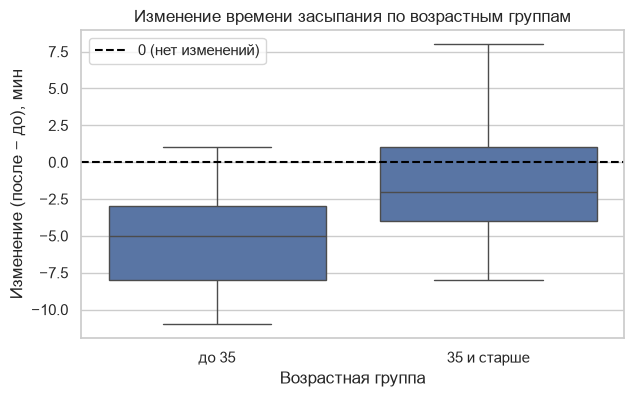

до 35: t = -6.367, p-value = 2.680e-06 -> значимо при α = 0.025
35 и старше: t = -1.424, p-value = 8.490e-02 -> не значимо при α = 0.025
Шапиро-Уилк до 35: p-value = 0.363
Шапиро-Уилк 35 и старше: p-value = 0.790
Уэлч (группы независимы): t = -3.249, p-value = 0.0024
Манн-Уитни (проверочный): U = 94, p-value = 0.0042
Разница средних эффектов: -3.98 мин


In [21]:
df_age = df_clean.dropna(subset=["age_group"])
print("Исключено участников с неизвестным возрастом:", len(df_clean) - len(df_age))

young = df_age.loc[df_age["age_group"] == "до 35", "diff"]
older = df_age.loc[df_age["age_group"] == "35 и старше", "diff"]
print(f"до 35: n = {len(young)}, среднее diff = {young.mean():.2f} мин")
print(f"35 и старше: n = {len(older)}, среднее diff = {older.mean():.2f} мин")

# График разностей по группам
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df_age, x="age_group", y="diff", ax=ax)
ax.axhline(0, color="black", linestyle="--", label="0 (нет изменений)")
ax.set_title("Изменение времени засыпания по возрастным группам")
ax.set_xlabel("Возрастная группа")
ax.set_ylabel("Изменение (после − до), мин")
ax.legend()
plt.show()

# Парный t-тест в каждой группе с поправкой Бонферрони (2 проверки)
alpha_bonf = ALPHA / 2
for name, s in [("до 35", young), ("35 и старше", older)]:
    sub = df_age[df_age["age_group"] == name]
    res = stats.ttest_rel(sub["after_min"], sub["before_min"], alternative="less")
    verdict = "значимо" if res.pvalue < alpha_bonf else "не значимо"
    print(f"{name}: t = {res.statistic:.3f}, p-value = {res.pvalue:.3e} -> {verdict} при α = {alpha_bonf}")

# Нормальность diff в каждой группе
for name, s in [("до 35", young), ("35 и старше", older)]:
    print(f"Шапиро-Уилк {name}: p-value = {stats.shapiro(s).pvalue:.3f}")

# Сравнение двух независимых групп
welch_groups = stats.ttest_ind(young, older, equal_var=False, alternative="two-sided")
mw = stats.mannwhitneyu(young, older, alternative="two-sided")
print(f"Уэлч (группы независимы): t = {welch_groups.statistic:.3f}, p-value = {welch_groups.pvalue:.4f}")
print(f"Манн-Уитни (проверочный): U = {mw.statistic:.0f}, p-value = {mw.pvalue:.4f}")
print(f"Разница средних эффектов: {young.mean() - older.mean():.2f} мин")

**Гипотезы:** $H_0$: $\mu_{d,\text{до 35}} = \mu_{d,\text{35+}}$ — средний эффект приложения одинаков в обеих группах; $H_1$: $\mu_{d,\text{до 35}} \ne \mu_{d,\text{35+}}$. Выбираем **двустороннюю** альтернативу: заранее нет обоснованного предположения, какой возрастной группе приложение должно помогать сильнее.

**Почему выборки независимые:** теперь сравниваются разности **разных людей** из двух групп, и каждый участник входит только в одну группу — пар между группами нет, поэтому используем тест для независимых выборок (Уэлч, без допущения равенства дисперсий; Манн-Уитни как проверочный). Нормальность `diff` в обеих группах не отвергается (p ≈ 0.36 и 0.79).

**Вывод:** 4 участника с неизвестным возрастом исключены. С поправкой Бонферрони (α = 0.025 на каждую из 2 проверок) сокращение времени засыпания значимо у участников **до 35 лет** (в среднем ≈ −5.3 мин, p ≈ 3·10⁻⁶), а у участников **35 и старше** эффект небольшой (≈ −1.3 мин) и статистически не подтверждён (p ≈ 0.085). Разница эффектов между группами ≈ 4 минуты значима (Уэлч p ≈ 0.002, Манн-Уитни p ≈ 0.004): приложение заметно сильнее помогает молодым пользователям — это стоит проверить отдельно в следующем исследовании.

---
## Задание 11. Оформление проекта (2 балла)

Итоговая работа сдаётся не просто файлом, а как **готовый воспроизводимый проект**. Требования см. в разделе «Что сдавать» ниже.

---
## Чек-лист самопроверки перед сдачей

**Анализ**
- [ ] Данные очищены по правилам 1–4 в правильном порядке; контрольные числа (44 строки, 40 заполненных `age_group`) совпали; ведётся журнал очистки.
- [ ] Столбец `age_group` создан корректно: возраст ровно 35 попадает в «35 и старше», пропуски возраста остались пропусками.
- [ ] Все задания 3–10 выполнены на `df_clean`, а не на исходном `df`.
- [ ] Гипотезы записаны формулами, определена разность и параметр $\mu_d$.
- [ ] Направление $H_1$ согласовано со знаком разности `after − before` и параметром `alternative` во **всех** тестах.
- [ ] Нормальность проверена для разностей, а не для исходных столбцов.
- [ ] Ручной расчёт t-критерия совпадает с `ttest_rel`.
- [ ] Для непарного теста порядок аргументов тот же, что и для парного.
- [ ] Все графики подписаны (заголовок, оси).
- [ ] Выводы написаны простым языком и содержат ограничения исследования.
- [ ] Ноутбук выполняется целиком без ошибок (**Restart & Run All**).

**Проект**
- [ ] Репозиторий публичный: ссылка открывается без авторизации (проверьте в режиме инкогнито).
- [ ] В репозитории есть `.ipynb`, `requirements.txt` и `README.md`.
- [ ] В чистом окружении работает цепочка: `pip install -r requirements.txt` → открыть ноутбук → Restart & Run All.
- [ ] Ссылка отправлена не позднее чем за 3 дня до защиты.

---
## Что сдавать

1. **Оформить итог отдельным проектом**, в котором будет `.ipynb` с вашим решением.
2. **В проекте должен быть файл `requirements.txt`** со всеми необходимыми библиотеками.
3. **Расположить проект на GitHub** (или аналоге: GitLab, Bitbucket) **в виде публичного репозитория**.
4. **Предоставить ссылку на GitHub-репозиторий не позднее чем за 3 дня до защиты проекта.**

### Рекомендации по оформлению

**Структура репозитория:**

```
project-name/
├── README.md          # краткое описание проекта, как запустить, главные выводы
├── requirements.txt   # зависимости
└── solution.ipynb     # ваше решение
```

Отдельный файл с данными не нужен: данные создаются ячейкой генерации внутри ноутбука.

**`README.md`** (достаточно 5–10 строк): название и цель проекта, краткое описание данных, как установить зависимости и запустить ноутбук,
главный вывод (1–2 предложения).

**`requirements.txt`:**
- перечислите библиотеки, которые **реально используются** в вашем ноутбуке (по одной на строку); не копируйте вслепую полный вывод `pip freeze`;
- подумайте, какие библиотеки нужны не для самого анализа, а для **работы ноутбука**: например, `plotly` требует `nbformat` для отображения графиков в Jupyter;
- рекомендуется указывать версии (например, `pandas>=2.0`): узнать установленную версию можно через `pip show имя_библиотеки` или `pip list`.

**Проверка воспроизводимости.** Создайте чистое виртуальное окружение (`python -m venv .venv`), установите зависимости командой `pip install -r requirements.txt`
и выполните ноутбук командой **Restart & Run All**. Если появилась ошибка `ModuleNotFoundError`, значит, в `requirements.txt` не хватает библиотеки.

**Что не стоит публиковать:** папку виртуального окружения (`.venv`), личные токены и пароли. Для исключения лишнего добавьте файл `.gitignore`.

**Срок.** Ссылку на репозиторий нужно отправить **не позднее чем за 3 дня до защиты**. Репозиторий должен оставаться неизменным до защиты, чтобы защищаемая версия совпадала с проверенной.